In [24]:
#تحميل الفيديو عبر الرابط باستخدام مكتبة yt_dlp في بايثون
# المكتبة مشbuilt in  لازم تتحمل من خلال pip install yt-dlp
import yt_dlp

video_url = "https://youtu.be/8QQdIieD4tw?si=FjIQXaUK4KEwuAAu"

video_save = {
    'outtmpl': 'video.mp4',
    'format': 'b[ext=mp4] / 18 / best',#اول شرط حمله افضل جودة mp4 لو متاحة و لو مش متاحة حمل الجودة 18 و لو مش متاحة حمل افضل جودة
    'extractor_args': {# هنا كل لازم نوضح الموقع اللي عايزين نحمل منه الفيديو و نوضح نوع الجهاز اللي هنستخدمه
        'youtube': {
            'player_client': ['android', 'web']# عشان ميرفضش لو لقاه بايثون فبيقوله اعتبره اندرويد او ويب
        }
    }
}

with yt_dlp.YoutubeDL(video_save) as ydl:
    ydl.download([video_url])

[youtube] Extracting URL: https://youtu.be/8QQdIieD4tw?si=FjIQXaUK4KEwuAAu
[youtube] 8QQdIieD4tw: Downloading webpage
[youtube] 8QQdIieD4tw: Downloading android player API JSON


[info] 8QQdIieD4tw: Downloading 1 format(s): 18
[download] Destination: video.mp4
[download] 100% of   69.94MiB in 00:00:27 at 2.50MiB/s     


In [9]:
%pip install yt-dlp opencv-python matplotlib

  Using cached yt_dlp-2026.8.19-py3-none-any.whl.metadata (183 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached numpy-2.5.3-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp313-cp313-win_amd64.whl.metadata (132 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached yt_dlp-2026.8.19-py3-none-any.whl (3.2 MB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import cv2
cap=cv2.VideoCapture('video.mp4')
frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)  # عدد الفريمات في الفيديو كله
fps = cap.get(cv2.CAP_PROP_FPS)  # سرعة الفيديو في الثانية
frame_width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)  # عرض الفيديو
frame_height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)  # ارتفاع الفيديو
cap.release()  # زي ما فتحنا الملف لازم نقفله بعد ما نخلص عشان ما يحصلش مشاكل
duration_s=frame_count / fps  # مدة الفيديو بالثانية    
duration_m=duration_s / 60  # مدة الفيديو بالدقيقة  
print(f"عدد الفريمات في الفيديو: {frame_count}")
print(f"سرعة الفيديو في الثانية: {fps}")
print(f"عرض الفيديو: {frame_width}")
print(f"ارتفاع الفيديو: {frame_height}")
print(f"مدة الفيديو بالثانية: {duration_s}")
print(f"مدة الفيديو بالدقيقة: {duration_m}")

عدد الفريمات في الفيديو: 111751.0
سرعة الفيديو في الثانية: 30.0
عرض الفيديو: 640.0
ارتفاع الفيديو: 322.0
مدة الفيديو بالثانية: 3725.0333333333333
مدة الفيديو بالدقيقة: 62.083888888888886


In [26]:
perecentage = [0.125,0.375,0.625,0.875]  #   النسب اللي عايزين ناخد منها الفريمات
#النسب دي ثابتة مهما كان الفيديو كام ساعة 
frams=[int(p * frame_count) for p in perecentage]
print(f" Frames: {frams}")

 Frames: [13968, 41906, 69844, 97782]


In [ ]:

import cv2

cap = cv2.VideoCapture("video.mp4")
for i,fram_num in enumerate(frams,start=1):
    cap.set(cv2.CAP_PROP_POS_FRAMES, fram_num)  # نروح للفريم اللي عايزينه
    success, frame = cap.read()  # كانها كاميرا بتلقط صورةم
    if success:
        text=f"(quarter {i}) Frame {fram_num}"  # نكتب على الصورة رقم الفريم
        cv2.putText(frame, text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)#تفاصيل الكتابة على الصورة
        file_name=f"frame_{i}.jpg"
        cv2.imwrite(file_name, frame)  # نحفظ الصورة في ملف 
cap.release()#غلق الفيديو بعد ما نخلص عشان ما يحصلش مشاكل



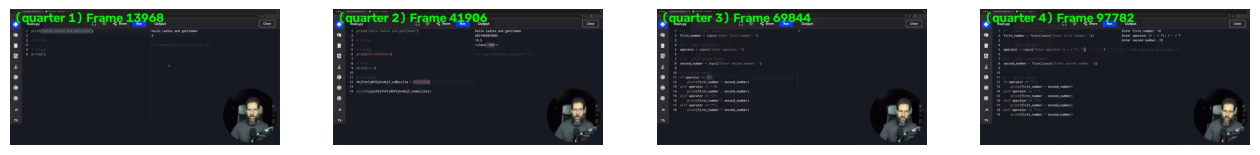

In [33]:
# مكتبة الرسم البياني وعرض الصور داخل النوت بوك بدلاً من فتح نوافذ خارجية
import matplotlib.pyplot as plt
import cv2

plt.figure(figsize=(16,4))#حجم الصورة في النوت بوك
for i in range(1,5):
    file_name=f"frame_{i}.jpg"
    img=cv2.imread(file_name)  # نقرأ الصورة من الملف
    img=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # تحويل الصورة من BGR إلى RGB
    plt.subplot(1,4,i)  # نرسم الصور في صف واحد و 4 أعمدة
    plt.imshow(img)  # عرض الصورة
    plt.axis('off')  # إخفاء المحاور
